# Home Map Viewer
View the LiDAR map saved by `build_map.py`

## Step 1 — Load the map

In [25]:
import open3d as o3d
import numpy as np
import matplotlib.pyplot as plt

MAP_FILE = 'home_map.pcd'

pcd = o3d.io.read_point_cloud(MAP_FILE)
points = np.asarray(pcd.points)

print(f"Map loaded: {len(points)} points")
print(f"X range: {points[:,0].min():.2f} m  to  {points[:,0].max():.2f} m")
print(f"Y range: {points[:,1].min():.2f} m  to  {points[:,1].max():.2f} m")

Map loaded: 75823 points
X range: -5.70 m  to  4.64 m
Y range: -3.69 m  to  2.39 m


## Step 2 — Top-down 2D map view

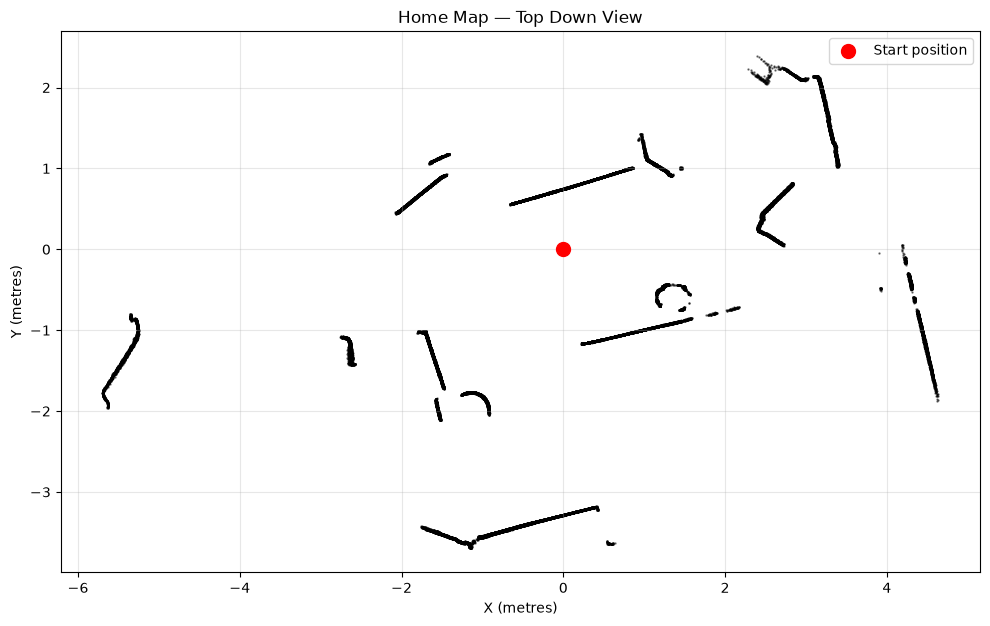

In [26]:
fig, ax = plt.subplots(figsize=(10, 10))

ax.scatter(points[:, 0], points[:, 1], s=0.5, c='black', alpha=0.5)

# robot start position
ax.scatter(0, 0, c='red', s=100, zorder=5, label='Start position')

ax.set_xlabel('X (metres)')
ax.set_ylabel('Y (metres)')
ax.set_title('Home Map — Top Down View')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Step 3 — Cleaned up map (remove noise)
Removes isolated points that are likely sensor noise.

After outlier removal : 68700 / 75823 points kept
After voxel downsample: 527 points
After 2nd pass        : 477 points


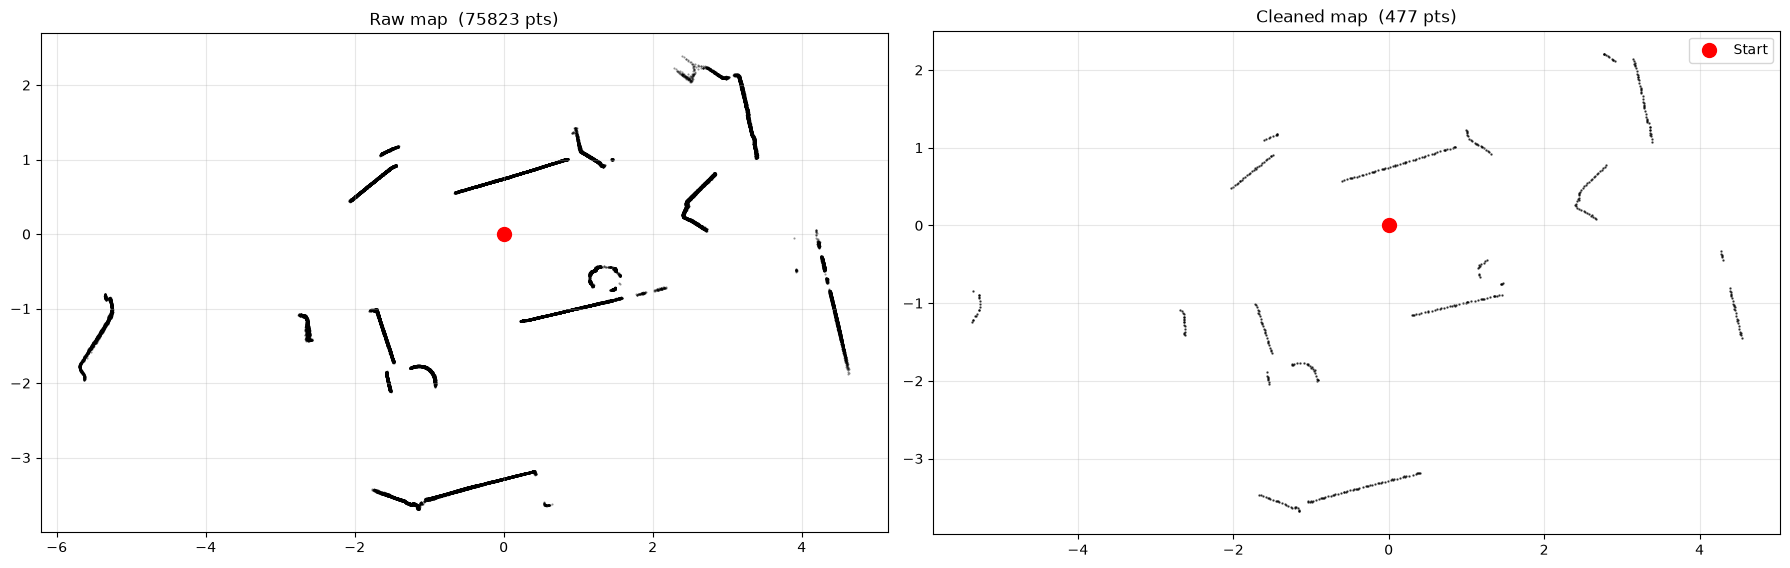

In [27]:
# Step 1: remove statistical outliers (isolated noise points)
pcd_clean, _ = pcd.remove_statistical_outlier(nb_neighbors=30, std_ratio=0.5)
print(f"After outlier removal : {len(pcd_clean.points)} / {len(pcd.points)} points kept")

# Step 2: voxel downsample — merges duplicate/dense points from overlapping scans
pcd_clean = pcd_clean.voxel_down_sample(voxel_size=0.04)
print(f"After voxel downsample: {len(pcd_clean.points)} points")

# Step 3: second pass outlier removal to catch anything left
pcd_clean, _ = pcd_clean.remove_statistical_outlier(nb_neighbors=10, std_ratio=1.0)
print(f"After 2nd pass        : {len(pcd_clean.points)} points")

points_clean = np.asarray(pcd_clean.points)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# raw
axes[0].scatter(points[:, 0], points[:, 1], s=0.3, c="black", alpha=0.4)
axes[0].scatter(0, 0, c="red", s=100, zorder=5)
axes[0].set_title(f"Raw map  ({len(points)} pts)")
axes[0].set_aspect("equal")
axes[0].grid(True, alpha=0.3)

# cleaned
axes[1].scatter(points_clean[:, 0], points_clean[:, 1], s=0.5, c="black", alpha=0.7)
axes[1].scatter(0, 0, c="red", s=100, zorder=5, label="Start")
axes[1].set_title(f"Cleaned map  ({len(points_clean)} pts)")
axes[1].set_aspect("equal")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## Step 4 — Zoom into a specific area

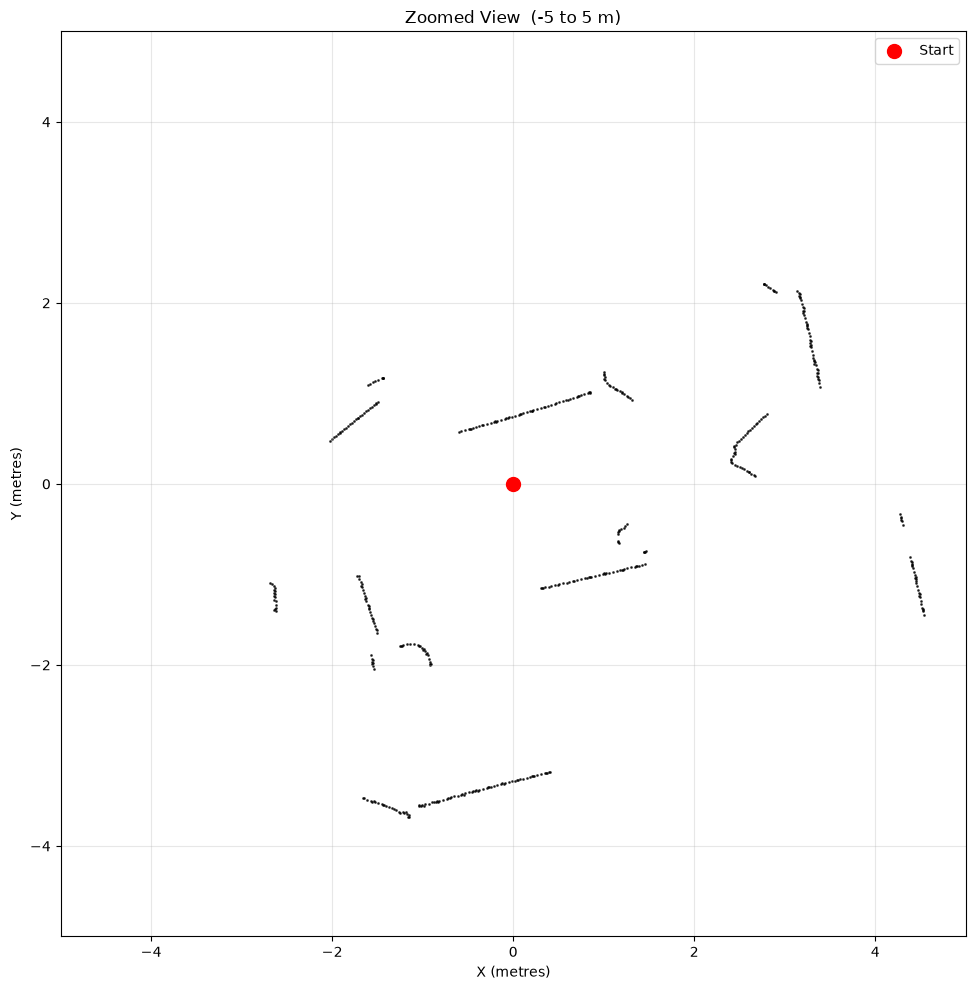

In [28]:
# change these to zoom into any part of your home
X_MIN, X_MAX = -5, 5
Y_MIN, Y_MAX = -5, 5

mask = (
    (points_clean[:, 0] >= X_MIN) & (points_clean[:, 0] <= X_MAX) &
    (points_clean[:, 1] >= Y_MIN) & (points_clean[:, 1] <= Y_MAX)
)
zoomed = points_clean[mask]

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(zoomed[:, 0], zoomed[:, 1], s=1, c='black', alpha=0.7)
ax.scatter(0, 0, c='red', s=100, zorder=5, label='Start')
ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)
ax.set_xlabel('X (metres)')
ax.set_ylabel('Y (metres)')
ax.set_title(f'Zoomed View  ({X_MIN} to {X_MAX} m)')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Step 5 — Save cleaned map as image

Saved as home_map.png


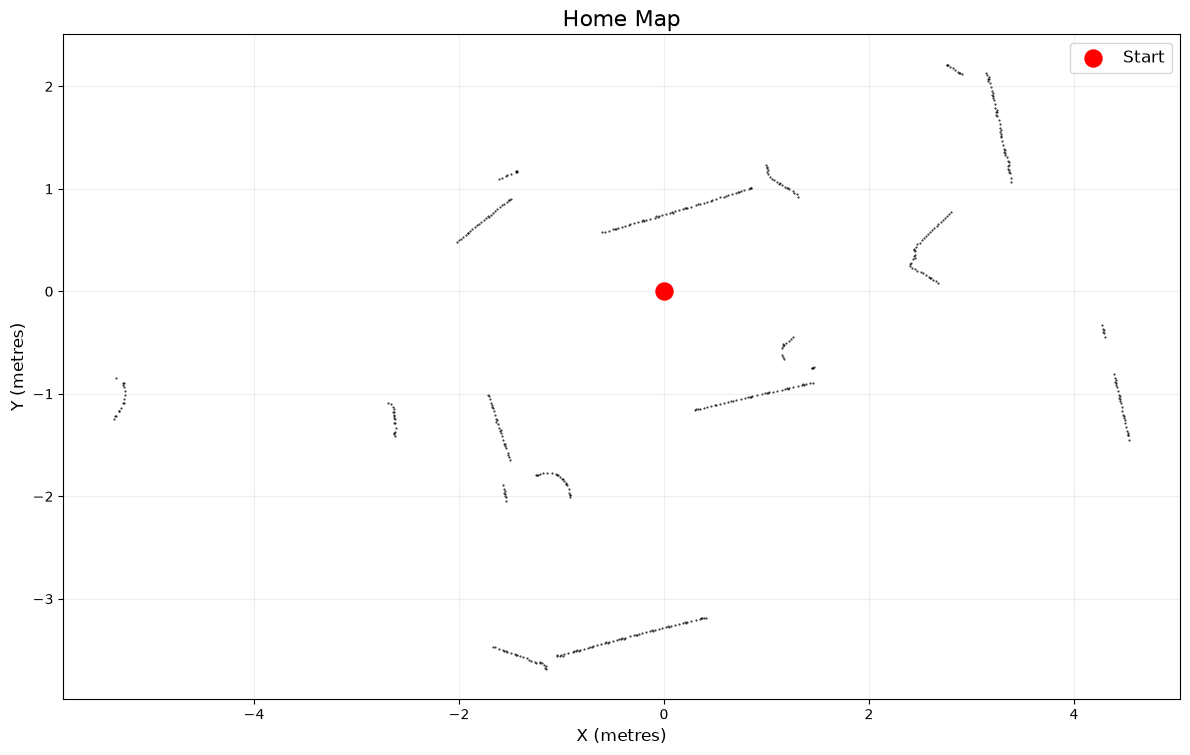

In [29]:
fig, ax = plt.subplots(figsize=(12, 12), facecolor='white')
ax.scatter(points_clean[:, 0], points_clean[:, 1], s=0.3, c='black', alpha=0.8)
ax.scatter(0, 0, c='red', s=150, zorder=5, label='Start')
ax.set_xlabel('X (metres)', fontsize=12)
ax.set_ylabel('Y (metres)', fontsize=12)
ax.set_title('Home Map', fontsize=16)
ax.set_aspect('equal')
ax.grid(True, alpha=0.2)
ax.legend(fontsize=12)
plt.tight_layout()
plt.savefig('home_map.png', dpi=150, bbox_inches='tight')
print("Saved as home_map.png")
plt.show()

## Step 6 — Save cleaned map back to PCD

In [24]:
o3d.io.write_point_cloud('home_map_clean.pcd', pcd_clean)
print(f"Cleaned map saved to home_map_clean.pcd ({len(points_clean)} points)")

Cleaned map saved to home_map_clean.pcd (4226 points)


In [30]:
!pwd


/home/priyanksharma/Desktop/lidarexp
